In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Retail Sales EDA Project Started!")

Retail Sales EDA Project Started!


In [3]:
df = pd.read_csv("retail-sales-dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category

In [6]:
# Convert mixed date formats into datetime
df['Date'] = pd.to_datetime(
    df['Date'],
    format='mixed',
    dayfirst=True
)

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Check updated data types
print("\nUpdated Data Types:")
print(df.dtypes)

Duplicate Records: 0

Updated Data Types:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [7]:
# Descriptive Statistics
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-06-27 15:47:31.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-04 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-23 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-09-21 06:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [8]:
# Gender Distribution
gender_counts = df['Gender'].value_counts()

print(gender_counts)

Gender
Female    510
Male      490
Name: count, dtype: int64


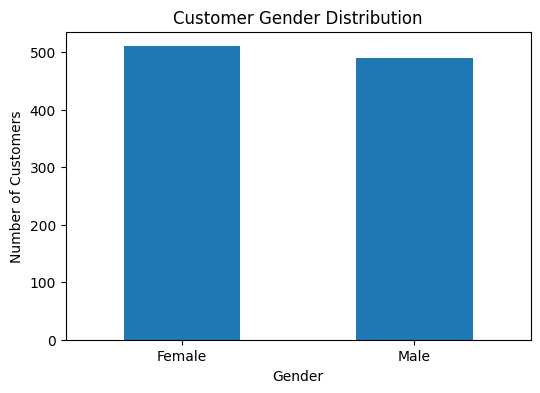

In [9]:
plt.figure(figsize=(6, 4))

gender_counts.plot(kind='bar')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.show()

In [10]:
category_counts = df['Product Category'].value_counts()

print(category_counts)

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


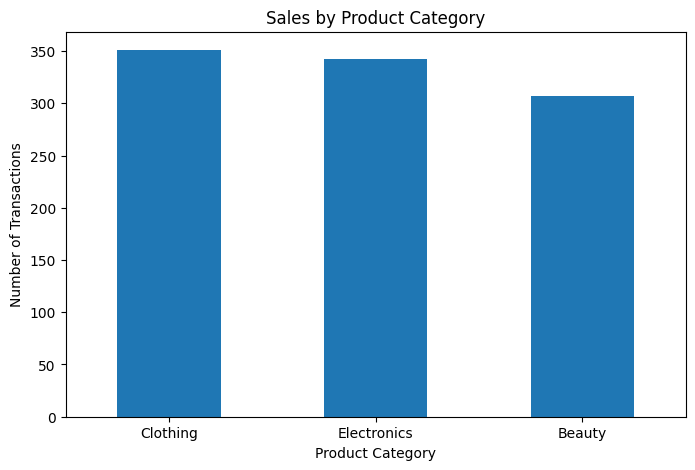

In [11]:
plt.figure(figsize=(8, 5))

category_counts.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)

plt.show()

In [12]:
category_revenue = df.groupby('Product Category')['Total Amount'].sum()

print("Revenue by Product Category:")
print(category_revenue)

Revenue by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


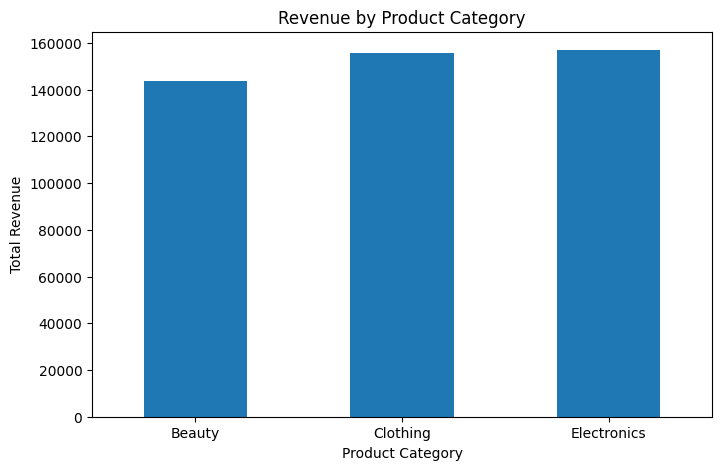

In [13]:
plt.figure(figsize=(8, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)

plt.show()

In [14]:
# Extract month from Date
df['Month'] = df['Date'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
2023-01    47190
2023-02    39430
2023-03    28750
2023-04    29715
2023-05    58590
2023-06    42205
2023-07    42505
2023-08    39155
2023-09    28605
2023-10    37130
2023-11    33020
2023-12    28175
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


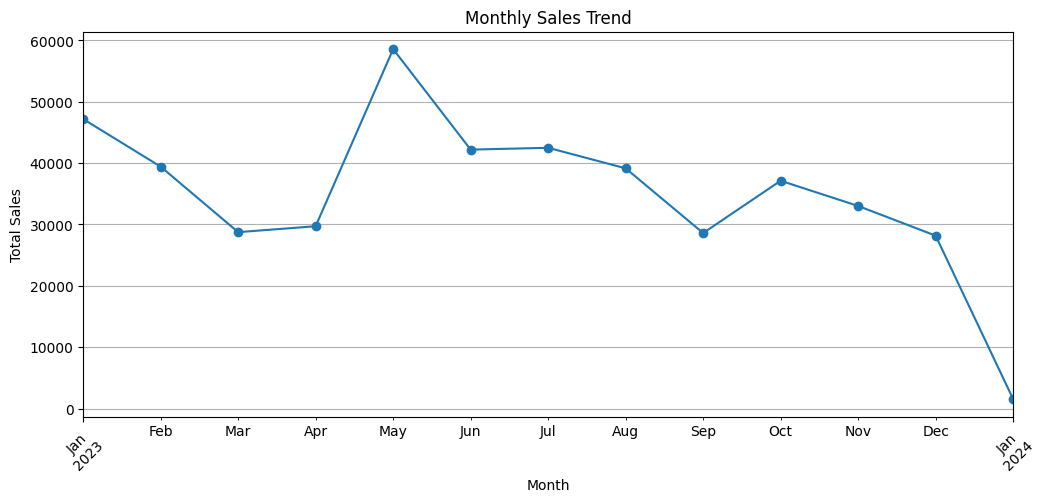

In [15]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

In [16]:
# Calculate age statistics
print("Average Age:", df['Age'].mean())
print("Minimum Age:", df['Age'].min())
print("Maximum Age:", df['Age'].max())
print("\nAge Group Distribution:")
print(df['Age'].value_counts(bins=5).sort_index())

Average Age: 41.392
Minimum Age: 18
Maximum Age: 64

Age Group Distribution:
(17.953, 27.2]    214
(27.2, 36.4]      175
(36.4, 45.6]      187
(45.6, 54.8]      208
(54.8, 64.0]      216
Name: count, dtype: int64


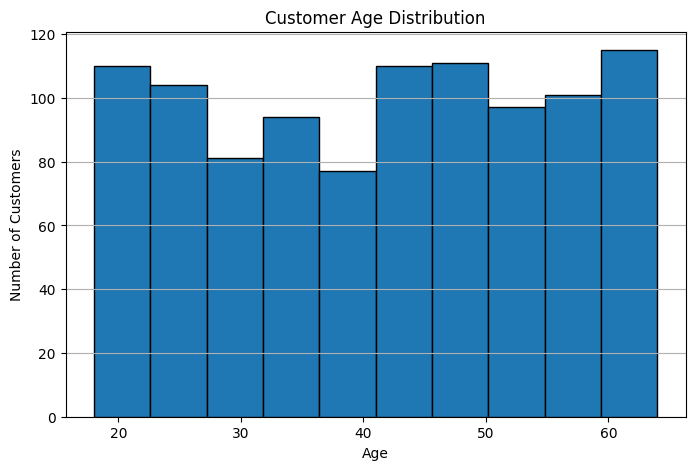

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.grid(axis='y')
plt.show()

In [18]:
# Select important numerical columns
numeric_data = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']]

# Calculate correlation
correlation = numeric_data.corr()

print(correlation)

                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000


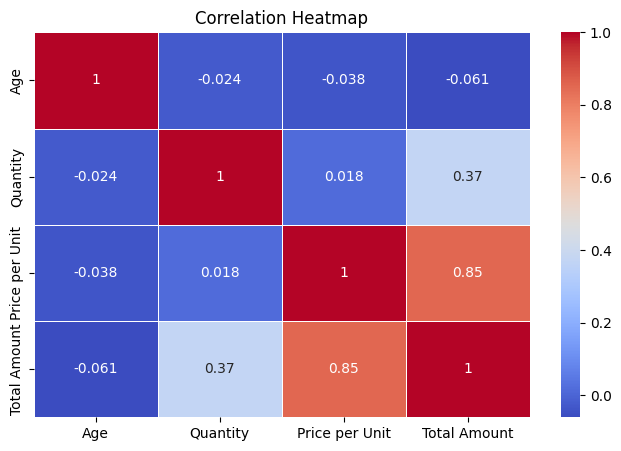

In [19]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [20]:
print("========== RETAIL SALES INSIGHTS ==========")

print("Total Transactions:", len(df))

print("Total Revenue:", df['Total Amount'].sum())

print("Average Transaction Amount:", df['Total Amount'].mean())

print("Highest Revenue Category:",
      df.groupby('Product Category')['Total Amount'].sum().idxmax())

print("Most Purchased Category:",
      df['Product Category'].value_counts().idxmax())

print("Average Customer Age:", df['Age'].mean())

print("Gender Distribution:")
print(df['Gender'].value_counts())

========== RETAIL SALES INSIGHTS ==========
Total Transactions: 1000
Total Revenue: 456000
Average Transaction Amount: 456.0
Highest Revenue Category: Electronics
Most Purchased Category: Clothing
Average Customer Age: 41.392
Gender Distribution:
Gender
Female    510
Male      490
Name: count, dtype: int64
